# Laboratorio 3 - La tarea de clasificación
## Caso: Ruta Alpes

**Curso:** ISIS2611 - Aprendizaje de Máquina

**Integrantes:**
- Camilo Molina Plata
- _(compañero/a)_

**Objetivo:** construir modelos de clasificación (regresión logística, árboles de decisión y Random Forest) que permitan anticipar si un conductor aceptará un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar el efecto del balanceo de clases y analizar posibles sesgos del uso de variables demográficas.

### Contenido
0. Configuración del entorno
1. Exploración de los datos
2. Limpieza y preparación de los datos
3. Regresión logística
4. Árboles de decisión
5. Random Forest
6. Balanceo de clases (SMOTE) en Restaurante(<20)
7. Tabla comparativa
8. Variables más relevantes
9. Análisis de resultados
10. Predicciones sobre los datos de prueba
11. Uso de herramientas de IA generativa

## 0. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2


## 1. Exploración de los datos

### 1.1 Carga de los datos y diccionario
Se cargan los tres archivos entregados: los datos etiquetados (`Lab3_Datos`), los datos sin etiqueta sobre los que se harán las predicciones finales (`Lab3_datos_Prueba`) y el diccionario de datos.

In [2]:
datos = pd.read_excel("datos/Lab3_Datos.xlsx")
prueba = pd.read_excel("datos/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("datos/Lab3_diccionario_Datos.xlsx")

print("Datos etiquetados:", datos.shape)
print("Datos de prueba:  ", prueba.shape)
diccionario

Datos etiquetados: (12664, 26)
Datos de prueba:   (20, 25)


,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y 20-50 indican los gastos pormedios por persona pa..."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [3]:
datos.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


### 1.2 Estructura y tipos de datos
Según el diccionario, todas las variables son categóricas (nominales u ordinales) excepto `temperatura`, que es numérica pero solo toma 3 valores fijos.

In [4]:
resumen = pd.DataFrame({
    "tipo_pandas": datos.dtypes.astype(str),
    "n_unicos": datos.nunique(),
    "n_nulos": datos.isna().sum(),
    "%_nulos": (datos.isna().mean() * 100).round(2),
})
resumen

,tipo_pandas,n_unicos,n_nulos,%_nulos
destino,str,3,0,0.00
acompanante,str,4,0,0.00
clima,str,3,0,0.00
temperatura,int64,3,0,0.00
hora,str,5,0,0.00
cupon,str,5,0,0.00
vigencia_cupon,str,2,0,0.00
genero,str,2,0,0.00
edad,str,8,0,0.00
estado_civil,str,5,0,0.00


In [5]:
# Valores posibles de cada variable (para detectar categorías mal escritas o inesperadas)
for col in datos.columns:
    print(f"{col}: {datos[col].value_counts(dropna=False).to_dict()}\n")

destino: {'Sin lugar urgente': 6270, 'Casa': 3233, 'Trabajo': 3161}

acompanante: {'Solo': 7296, 'Amigo(s)': 3291, 'Pareja': 1072, 'Hijo(s)': 1005}

clima: {'Soleado': 10052, 'Nevado': 1404, 'Lluvioso': 1208}

temperatura: {80: 6513, 55: 3836, 30: 2315}

hora: {'6:00 p.m.': 3224, '7:00 a.m.': 3161, '10:00 a.m.': 2271, '2:00 p.m.': 2005, '10:00 p.m.': 2003}

cupon: {'Cafetería': 3986, 'Restaurante(<20)': 2776, 'Comida para llevar': 2393, 'Bar': 2017, 'Restaurante(20-50)': 1492}

vigencia_cupon: {'1 día': 7081, '2 horas': 5583}

genero: {'Femenino': 6501, 'Masculino': 6163}

edad: {'21': 2652, '26': 2555, '31': 2033, '50 o más': 1785, '36': 1316, '41': 1091, '46': 685, 'menor de 21': 547}

estado_civil: {'Casado(a)': 5092, 'Soltero(a)': 4742, 'Unión libre': 2185, 'Divorciado(a)': 515, 'Viudo(a)': 130}

tiene_hijos: {'No': 7421, 'Sí': 5243}

educacion: {'Estudios universitarios sin título': 4344, 'Pregrado': 4329, 'Posgrado (Maestría o Doctorado)': 1849, 'Técnico/Tecnólogo': 1151, 'Bachil

### 1.3 Valores faltantes

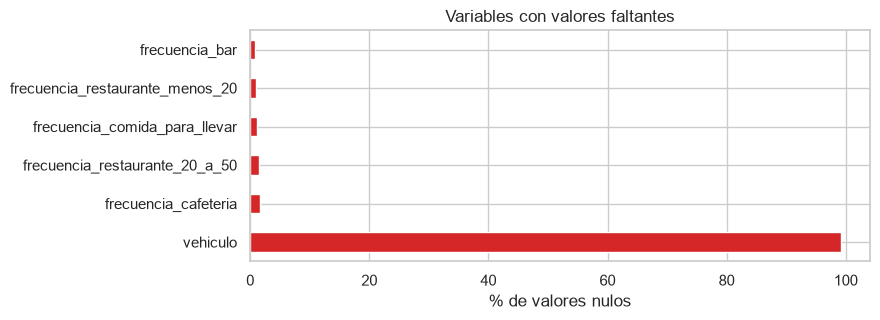

,n_nulos,pct
vehiculo,12556,99.15
frecuencia_cafeteria,217,1.71
frecuencia_restaurante_20_a_50,189,1.49
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_bar,107,0.84


In [6]:
nulos = datos.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
ax = (nulos / len(datos) * 100).plot(kind="barh", figsize=(8, 3), color="tab:red")
ax.set_xlabel("% de valores nulos")
ax.set_title("Variables con valores faltantes")
plt.show()
nulos.to_frame("n_nulos").assign(pct=lambda x: (x.n_nulos / len(datos) * 100).round(2))

### 1.4 Registros duplicados
Se revisan duplicados exactos y también registros con las mismas características pero **etiqueta distinta** (conflictivos).

In [7]:
X_cols = [c for c in datos.columns if c != "acepta_cupon"]
print("Duplicados exactos (incluyendo la etiqueta):", datos.duplicated().sum())
print("Duplicados en las características:          ", datos.duplicated(subset=X_cols).sum())

conflictos = datos.groupby(X_cols, dropna=False)["acepta_cupon"].nunique()
print("Grupos de características con etiquetas en conflicto:", (conflictos > 1).sum())

Duplicados exactos (incluyendo la etiqueta): 74
Duplicados en las características:           97


Grupos de características con etiquetas en conflicto: 23


### 1.5 Variables constantes y redundantes
Se revisan relaciones que el diccionario sugiere entre variables: `clima` y `temperatura`, las variables de distancia (`tiempo_cupon_mayor_*`) y las de dirección.

In [8]:
print("Variables con un único valor:", [c for c in datos.columns if datos[c].nunique(dropna=False) == 1])

Variables con un único valor: ['tiempo_cupon_mayor_5min']


In [9]:
pd.crosstab(datos["clima"], datos["temperatura"])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


In [10]:
print("¿direccion_opuesta es siempre lo contrario de misma_direccion?",
      ((datos["misma_direccion"] == "Sí") == (datos["direccion_opuesta"] == "No")).all())
pd.crosstab(datos["tiempo_cupon_mayor_15min"], datos["tiempo_cupon_mayor_25min"])

¿direccion_opuesta es siempre lo contrario de misma_direccion? True


tiempo_cupon_mayor_25min,No,Sí
tiempo_cupon_mayor_15min,,
No,5551,0
Sí,5602,1511


### 1.5.1 Consistencia lógica entre variables
Se buscan combinaciones de valores que, aunque individualmente válidas, son contradictorias o poco plausibles entre sí.

In [11]:
# Viaja con hijos pero reporta no tener hijos
inc_hijos = (datos["acompanante"] == "Hijo(s)") & (datos["tiene_hijos"] == "No")
print("acompanante = Hijo(s) y tiene_hijos = No:", inc_hijos.sum())
print(datos[inc_hijos]["cupon"].value_counts().to_dict(), "\n")

# Jubilados jóvenes
jubilados = datos[datos["ocupacion"] == "Jubilado(a)"]
pd.crosstab(jubilados["edad"], jubilados["cupon"], margins=True)

acompanante = Hijo(s) y tiene_hijos = No: 17
{'Restaurante(20-50)': 5, 'Cafetería': 4, 'Restaurante(<20)': 3, 'Bar': 3, 'Comida para llevar': 2} 



cupon,Bar,Cafetería,Comida para llevar,Restaurante(20-50),Restaurante(<20),All
edad,,,,,,
26,3,10,3,2,4,22
36,2,10,4,0,6,22
46,4,13,6,3,8,34
50 o más,66,130,77,50,93,416
All,75,163,90,55,111,494


In [12]:
# Los mismos casos en los datos de prueba
print("Prueba - Hijo(s) sin hijos:", ((prueba["acompanante"] == "Hijo(s)") & (prueba["tiene_hijos"] == "No")).sum())
print("Prueba - edades de jubilados:", prueba.loc[prueba["ocupacion"] == "Jubilado(a)", "edad"].tolist())

Prueba - Hijo(s) sin hijos: 0
Prueba - edades de jubilados: ['50 o más']


### 1.6 Subconjuntos por tipo de cupón y distribución de `acepta_cupon`
El estudio se centra en los cupones de **Cafetería** y **Restaurante(<20)**, por lo que se construye un subconjunto para cada uno y se analiza la distribución de la variable objetivo.

In [13]:
pd.crosstab(datos["cupon"], datos["acepta_cupon"], margins=True)

acepta_cupon,No,Sí,All
cupon,,,
Bar,1190,827,2017
Cafetería,1997,1989,3986
Comida para llevar,633,1760,2393
Restaurante(20-50),834,658,1492
Restaurante(<20),814,1962,2776
All,5468,7196,12664


Cafetería: 3986 registros
                 n   pct
acepta_cupon            
No            1997  50.1
Sí            1989  49.9 

Restaurante(<20): 2776 registros
                 n   pct
acepta_cupon            
Sí            1962  70.7
No             814  29.3 



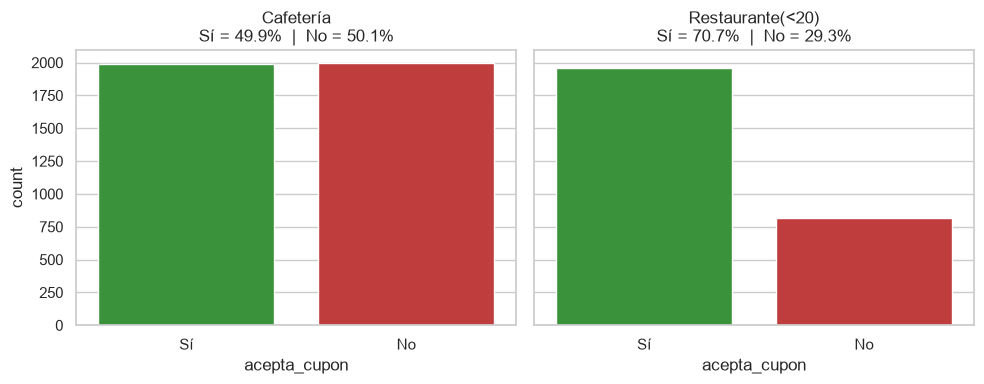

In [14]:
subconjuntos = {c: datos[datos["cupon"] == c].copy() for c in CUPONES}

for c, df in subconjuntos.items():
    print(f"{c}: {df.shape[0]} registros")
    print(df["acepta_cupon"].value_counts().to_frame("n").assign(pct=lambda x: (x.n / x.n.sum() * 100).round(1)), "\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (c, df) in zip(axes, subconjuntos.items()):
    sns.countplot(data=df, x="acepta_cupon", order=["Sí", "No"], ax=ax, hue="acepta_cupon", palette={"Sí": "tab:green", "No": "tab:red"}, legend=False)
    pct = df["acepta_cupon"].value_counts(normalize=True) * 100
    ax.set_title(f"{c}\nSí = {pct['Sí']:.1f}%  |  No = {pct['No']:.1f}%")
    ax.set_xlabel("acepta_cupon")
plt.tight_layout()
plt.show()

In [15]:
# Calidad de datos dentro de cada subconjunto
calidad = pd.DataFrame({
    c: {
        "registros": len(df),
        "duplicados_exactos": df.duplicated().sum(),
        "duplicados_en_X": df.duplicated(subset=X_cols).sum(),
        **{f"nulos_{col}": df[col].isna().sum() for col in nulos.index},
    }
    for c, df in subconjuntos.items()
})
calidad

,Cafetería,Restaurante(<20)
registros,3986,2776
duplicados_exactos,7,7
duplicados_en_X,11,10
nulos_vehiculo,3949,2751
nulos_frecuencia_cafeteria,72,47
nulos_frecuencia_restaurante_20_a_50,55,43
nulos_frecuencia_comida_para_llevar,57,34
nulos_frecuencia_restaurante_menos_20,50,27
nulos_frecuencia_bar,37,23


### 1.7 Relación de las variables con la aceptación en cada subconjunto
Se calcula la tasa de aceptación (% de "Sí") por categoría de algunas variables de contexto y de perfil, para tener una primera intuición de qué factores influyen en cada cupón.

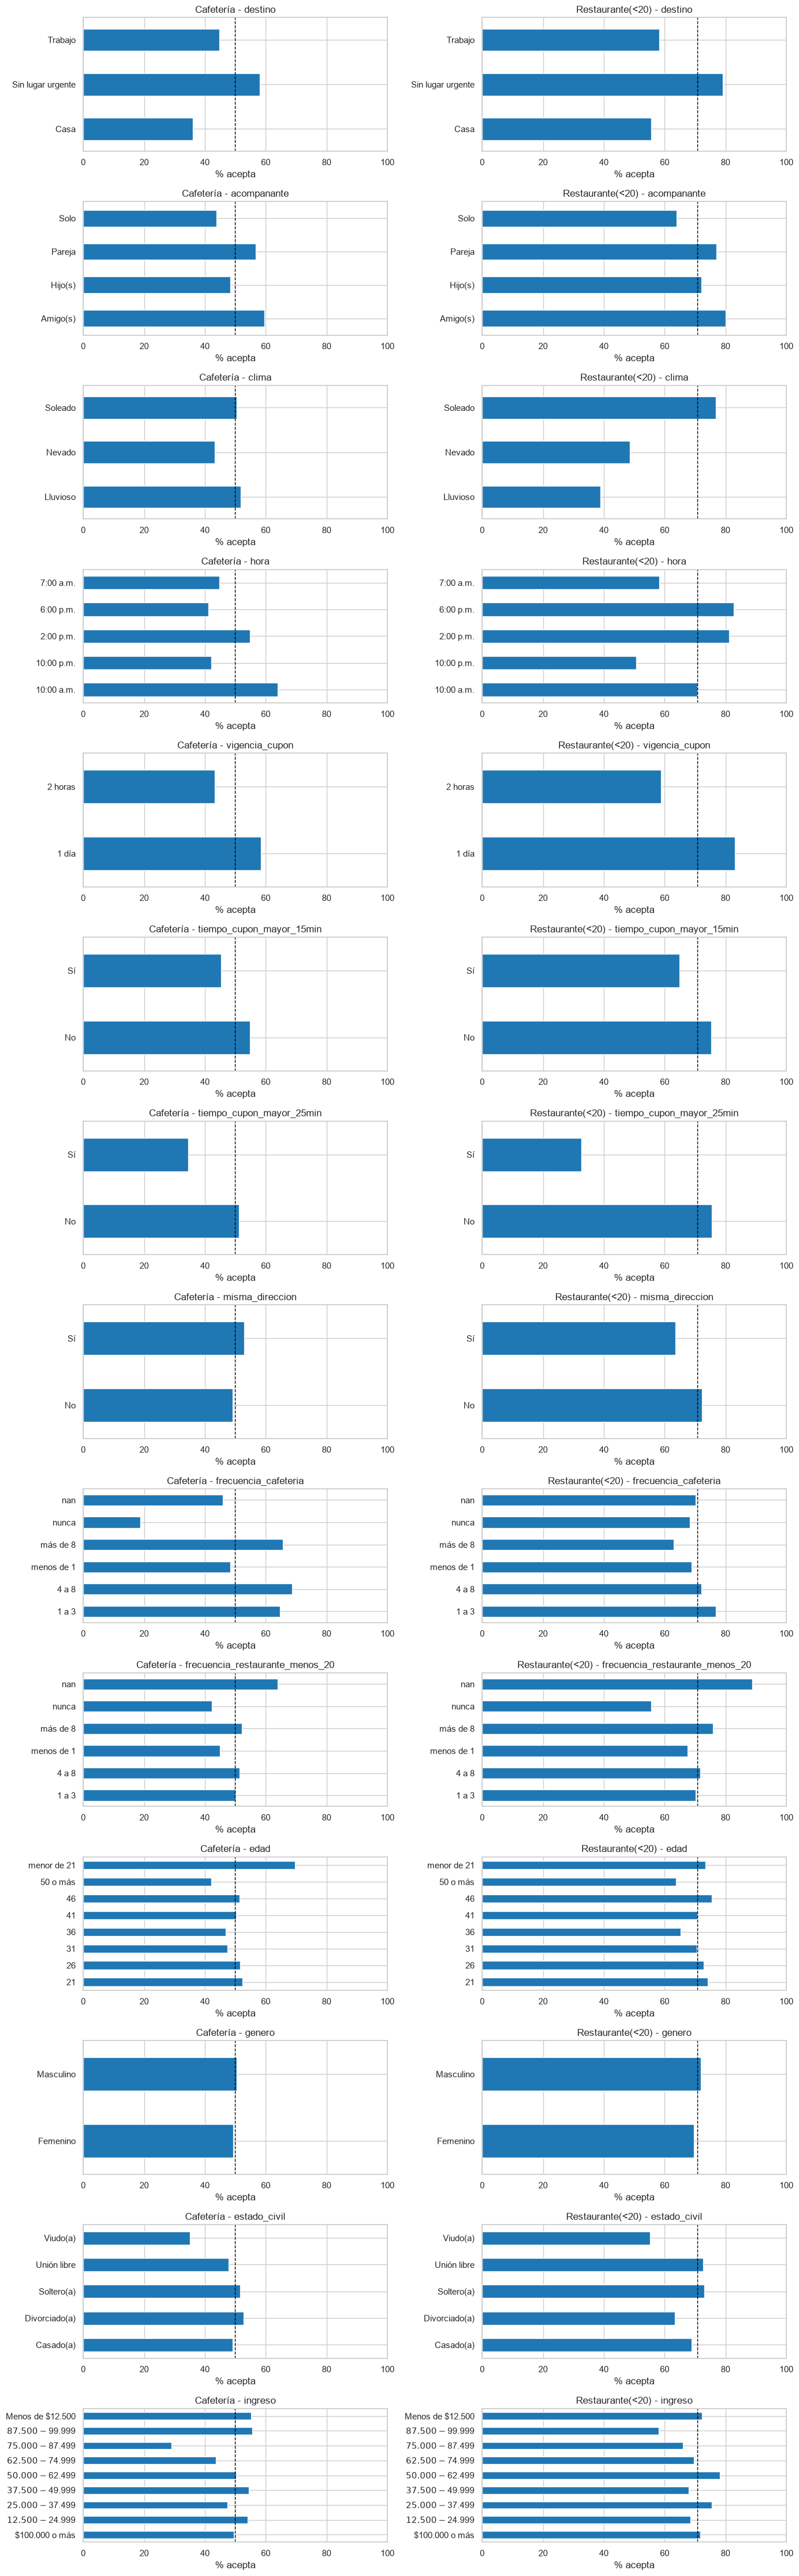

In [16]:
def tasa_aceptacion(df, col):
    return (df.groupby(col, dropna=False)["acepta_cupon"]
              .apply(lambda s: (s == "Sí").mean() * 100)
              .rename("tasa_aceptacion_%"))

vars_exploracion = ["destino", "acompanante", "clima", "hora", "vigencia_cupon",
                    "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion",
                    "frecuencia_cafeteria", "frecuencia_restaurante_menos_20",
                    "edad", "genero", "estado_civil", "ingreso"]

fig, axes = plt.subplots(len(vars_exploracion), 2, figsize=(14, 3.2 * len(vars_exploracion)))
for i, col in enumerate(vars_exploracion):
    for j, (c, df) in enumerate(subconjuntos.items()):
        ax = axes[i, j]
        tasa_aceptacion(df, col).plot(kind="barh", ax=ax, color="tab:blue")
        ax.axvline((df["acepta_cupon"] == "Sí").mean() * 100, color="black", ls="--", lw=1)
        ax.set_xlim(0, 100)
        ax.set_title(f"{c} - {col}")
        ax.set_xlabel("% acepta")
        ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 1.8 Datos de prueba
Se verifica que los datos sin etiquetar tengan la misma estructura que los de entrenamiento.

In [17]:
print("Columnas que difieren:", set(datos.columns) ^ set(prueba.columns))
print(prueba["cupon"].value_counts(), "\n")
print("Nulos en prueba:\n", prueba.isna().sum()[prueba.isna().sum() > 0])

Columnas que difieren: {'acepta_cupon'}
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64 

Nulos en prueba:
 vehiculo    20
dtype: int64


### 1.9 Conclusiones de la exploración

**Calidad de los datos**
- **`vehiculo`** tiene más del 99% de valores nulos (solo ~108 registros con valor, y en prueba está vacía en todas las filas). No aporta información útil.
- **`tiempo_cupon_mayor_5min`** es **constante** (siempre "Sí"), por lo que no tiene poder predictivo.
- **`direccion_opuesta`** es **exactamente el complemento** de `misma_direccion`: es redundante.
- **`temperatura`** está casi determinada por `clima` (Lluvioso → 55, Nevado → 30, Soleado → 30/55/80). Aporta poca información adicional, aunque distingue días soleados fríos de cálidos.
- Las variables `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` están anidadas (si es mayor a 25 min, también es mayor a 15 min): juntas codifican una distancia ordinal de 3 niveles.
- Las cinco variables de **frecuencia** tienen entre 0.8% y 1.7% de valores nulos.
- Hay **74 duplicados exactos** en el total de datos (7 en cada subconjunto de interés) y unos pocos registros con las mismas características pero **etiqueta en conflicto**.
- **Inconsistencia lógica:** 17 registros viajan con `acompanante = Hijo(s)` pero reportan `tiene_hijos = No` (4 en Cafetería y 3 en Restaurante(<20)). No es posible saber cuál de los dos campos es el erróneo (incluso "Hijo(s)" podría referirse a hijastros o sobrinos).
- **Valores sospechosos:** hay jubilados de 26 y 36 años (44 registros en total; 20 en Cafetería y 10 en Restaurante(<20)). Son poco frecuentes, pero plausibles (p. ej. jubilación por invalidez), por lo que se consideran posibles atípicos y no errores.
- No se encontraron categorías mal escritas ni espacios sobrantes; los valores corresponden a los del diccionario.

**Distribución de `acepta_cupon`**
- **Cafetería** (3986 registros): prácticamente **balanceada** (~50% Sí / ~50% No).
- **Restaurante(<20)** (2776 registros): **desbalanceada** (~71% Sí / ~29% No). La **clase minoritaria es "No"** (rechazo), lo que hay que tener en cuenta al evaluar el recall de la clase minoritaria en la Actividad 6.

**Primeras intuiciones** (diferencia entre la categoría con mayor y menor tasa de aceptación, considerando categorías con al menos 50 registros)
- **Cafetería:** la variable más relacionada es `frecuencia_cafeteria` (~50 puntos porcentuales de diferencia entre quienes nunca van y quienes van seguido), seguida de `ocupacion`, `edad`, `ingreso`, `hora` y `destino`.
- **Restaurante(<20):** dominan las variables de **contexto**: la distancia (`tiempo_cupon_mayor_25min`, ~43 p.p.), el `clima`, la `hora`, la `vigencia_cupon` y el `destino`; la frecuencia de visita a este tipo de restaurante pesa menos que en Cafetería.
- `genero` y `tiene_hijos` casi no cambian la tasa de aceptación en ninguno de los dos cupones (< 3 p.p.). En cambio, variables demográficas como `edad`, `ingreso` y `ocupacion` sí muestran diferencias importantes, sobre todo en Cafetería; esto es relevante para el análisis de sesgos (pueden actuar como predictores directos o como *proxies* de otros factores).
- Estas son relaciones univariadas (una variable a la vez); los modelos permitirán ver su efecto en conjunto.


## 2. Limpieza y preparación de los datos

Con base en los hallazgos de la exploración se toman las siguientes decisiones:

| Problema detectado | Decisión | Justificación |
|:---|:---|:---|
| `vehiculo` con >99% de nulos (100% en prueba) | Eliminar la columna | No hay información suficiente para imputarla ni para aprender de ella. |
| `tiempo_cupon_mayor_5min` constante | Eliminar la columna | Una variable con un solo valor no puede discriminar entre clases. |
| `direccion_opuesta` = complemento de `misma_direccion` | Eliminar `direccion_opuesta` | Es información duplicada; mantener ambas solo agrega colinealidad perfecta (problemática en regresión logística). |
| `cupon` constante dentro de cada subconjunto | Excluirla de las características | Al entrenar un modelo por tipo de cupón, deja de aportar información. |
| Duplicados exactos (7 en cada subconjunto) | Eliminarlos | Evitan que un mismo registro aparezca en entrenamiento y test a la vez (sobreestimando el desempeño). Al ser tan pocos, no alteran la distribución. |
| Registros con características iguales y etiqueta en conflicto | Mantenerlos | Reflejan el ruido real del problema (dos conductores con el mismo perfil pueden decidir distinto); no hay criterio para elegir cuál etiqueta es "correcta". |
| `acompanante = Hijo(s)` con `tiene_hijos = No` | Mantener y documentar | No es posible saber cuál campo es erróneo; corregirlo sería adivinar y eliminarlos (3-4 por subconjunto) no cambia los resultados. |
| Jubilados de 26 y 36 años | Mantener y documentar | Son plausibles (jubilación anticipada o por invalidez); no hay evidencia de que sean errores. |
| Nulos en las variables de frecuencia (<2%) | Imputar con la **moda**, dentro del pipeline | Son variables categóricas con pocos nulos; la moda es una imputación razonable. Hacerlo dentro del pipeline evita fuga de información (la moda se calcula solo con el entrenamiento de cada *fold*) y permite que el modelo maneje nulos en producción. |
| `temperatura` casi determinada por `clima` | Mantenerla como numérica | Distingue días soleados fríos (30°F) de cálidos (80°F), información que `clima` no tiene. |
| Variables ordinales en texto (`hora`, `edad`, `educacion`, `ingreso`, frecuencias) | **Codificación ordinal** con el orden del diccionario | Conserva el orden natural de las categorías con una sola columna por variable. |
| Variables nominales | **One-hot encoding** | No tienen orden; una codificación numérica impondría un orden artificial. |
| Escalas distintas (solo para regresión logística) | `StandardScaler` sobre ordinales y numéricas | La regularización L1/L2 penaliza los coeficientes, por lo que las variables deben estar en escalas comparables. Los árboles y Random Forest no lo necesitan. |

### 2.1 Limpieza de columnas y duplicados

In [18]:
COLS_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta"]

def limpiar(df, eliminar_duplicados=True):
    df = df.drop(columns=COLS_ELIMINAR)
    if eliminar_duplicados:
        df = df.drop_duplicates()
    return df.reset_index(drop=True)

datos_limpios = {c: limpiar(df) for c, df in subconjuntos.items()}
# Los datos de prueba no se deduplican: se debe predecir cada una de sus filas
prueba_limpia = limpiar(prueba, eliminar_duplicados=False)

for c in CUPONES:
    print(f"{c}: {subconjuntos[c].shape} -> {datos_limpios[c].shape}")
print(f"Prueba: {prueba.shape} -> {prueba_limpia.shape}")

Cafetería: (3986, 26) -> (3979, 23)
Restaurante(<20): (2776, 26) -> (2769, 23)
Prueba: (20, 25) -> (20, 22)


### 2.2 Definición de los tipos de variables y del orden de las ordinales
El orden de las categorías ordinales se toma del diccionario de datos. Se verifica que todos los valores presentes en los datos estén contemplados.

In [19]:
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

ORDINALES = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    "frecuencia_bar": ORDEN_FRECUENCIA,
    "frecuencia_cafeteria": ORDEN_FRECUENCIA,
    "frecuencia_comida_para_llevar": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_menos_20": ORDEN_FRECUENCIA,
    "frecuencia_restaurante_20_a_50": ORDEN_FRECUENCIA,
}
NUMERICAS = ["temperatura"]
NOMINALES = ["destino", "acompanante", "clima", "vigencia_cupon", "genero", "estado_civil", "tiene_hijos",
             "ocupacion", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "misma_direccion"]
OBJETIVO = "acepta_cupon"

# Verificación: todas las columnas están clasificadas y todos los valores ordinales están en el orden definido
columnas_x = set(datos_limpios[CUPONES[0]].columns) - {OBJETIVO, "cupon"}
assert columnas_x == set(ORDINALES) | set(NUMERICAS) | set(NOMINALES), columnas_x ^ (set(ORDINALES) | set(NUMERICAS) | set(NOMINALES))
for col, orden in ORDINALES.items():
    for df in [*datos_limpios.values(), prueba_limpia]:
        faltantes = set(df[col].dropna()) - set(orden)
        assert not faltantes, f"{col}: {faltantes}"
print(f"OK: {len(ORDINALES)} ordinales, {len(NUMERICAS)} numérica, {len(NOMINALES)} nominales")

OK: 9 ordinales, 1 numérica, 11 nominales


### 2.3 Partición en entrenamiento y test
Para cada tipo de cupón se separa un 20% de los datos como conjunto de **test**, que solo se usará para la evaluación final de los modelos (Actividad 7). La partición es **estratificada** por `acepta_cupon` para conservar la proporción de clases, algo especialmente importante en Restaurante(<20), que está desbalanceado.

La variable objetivo se codifica como **1 = Sí (acepta)** y **0 = No (rechaza)**, de modo que las métricas de precisión, recall y F1 se calculan por defecto sobre la aceptación del cupón.

In [20]:
from sklearn.model_selection import train_test_split

def separar_X_y(df):
    X = df.drop(columns=[OBJETIVO, "cupon"])
    y = (df[OBJETIVO] == "Sí").astype(int)
    return X, y

particiones = {}
for c in CUPONES:
    X, y = separar_X_y(datos_limpios[c])
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    particiones[c] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

pd.DataFrame({
    c: {
        "n_train": len(p["y_train"]), "n_test": len(p["y_test"]),
        "% Sí train": round(p["y_train"].mean() * 100, 1), "% Sí test": round(p["y_test"].mean() * 100, 1),
    }
    for c, p in particiones.items()
})

,Cafetería,Restaurante(<20)
n_train,3183.0,2215.0
n_test,796.0,554.0
% Sí train,49.8,70.7
% Sí test,49.9,70.8


### 2.4 Preprocesamiento como parte del pipeline
El preprocesamiento se define con un `ColumnTransformer` que luego se integrará como primer paso del `Pipeline` de cada modelo. Así, la imputación y la codificación se ajustan **solo con los datos de entrenamiento** de cada *fold* durante la validación cruzada, evitando fuga de información.

- **Ordinales:** imputación con la moda → `OrdinalEncoder` con el orden del diccionario (→ `StandardScaler` en regresión logística).
- **Numéricas:** imputación con la moda (→ `StandardScaler` en regresión logística).
- **Nominales:** imputación con la moda → `OneHotEncoder` (`handle_unknown="ignore"` para no fallar si aparece una categoría nueva en producción).

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

def crear_preprocesador(escalar=False):
    pasos_ordinales = [
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OrdinalEncoder(categories=list(ORDINALES.values()),
                                     handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    pasos_numericos = [("imputar", SimpleImputer(strategy="most_frequent"))]
    if escalar:
        pasos_ordinales.append(("escalar", StandardScaler()))
        pasos_numericos.append(("escalar", StandardScaler()))

    return ColumnTransformer([
        ("ordinales", Pipeline(pasos_ordinales), list(ORDINALES)),
        ("numericas", Pipeline(pasos_numericos), NUMERICAS),
        ("nominales", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), NOMINALES),
    ])

# Ejemplo: resultado del preprocesamiento sobre el entrenamiento de Cafetería
pre = crear_preprocesador(escalar=False)
X_ejemplo = pre.fit_transform(particiones["Cafetería"]["X_train"])
print("Dimensión antes:", particiones["Cafetería"]["X_train"].shape, "-> después:", X_ejemplo.shape)
print("Nulos después del preprocesamiento:", np.isnan(X_ejemplo).sum())
pd.DataFrame(X_ejemplo, columns=pre.get_feature_names_out()).head()

Dimensión antes: (3183, 21) -> después: (3183, 62)
Nulos después del preprocesamiento: 0


,ordinales__hora,ordinales__edad,ordinales__educacion,ordinales__ingreso,ordinales__frecuencia_bar,ordinales__frecuencia_cafeteria,ordinales__frecuencia_comida_para_llevar,ordinales__frecuencia_restaurante_menos_20,ordinales__frecuencia_restaurante_20_a_50,numericas__temperatura,nominales__destino_Casa,nominales__destino_Sin lugar urgente,nominales__destino_Trabajo,nominales__acompanante_Amigo(s),nominales__acompanante_Hijo(s),nominales__acompanante_Pareja,nominales__acompanante_Solo,nominales__clima_Lluvioso,nominales__clima_Nevado,nominales__clima_Soleado,nominales__vigencia_cupon_1 día,nominales__vigencia_cupon_2 horas,nominales__genero_Femenino,nominales__genero_Masculino,nominales__estado_civil_Casado(a),...,nominales__ocupacion_Computación y Matemáticas,nominales__ocupacion_Construcción y Extracción,nominales__ocupacion_Cuidado Personal y Servicios,nominales__ocupacion_Desempleado(a),"nominales__ocupacion_Educación, Formación y Bibliotecología",nominales__ocupacion_Estudiante,nominales__ocupacion_Gerencia,"nominales__ocupacion_Instalación, Mantenimiento y Reparación",nominales__ocupacion_Jubilado(a),nominales__ocupacion_Limpieza y Mantenimiento de Edificios,nominales__ocupacion_Negocios y Finanzas,nominales__ocupacion_Preparación y Servicio de Alimentos,nominales__ocupacion_Producción,nominales__ocupacion_Profesionales y Técnicos de la Salud,nominales__ocupacion_Servicios Comunitarios y Sociales,nominales__ocupacion_Servicios de Protección y Seguridad,nominales__ocupacion_Transporte y Manejo de Materiales,nominales__ocupacion_Ventas y afines,nominales__ocupacion_Área Legal,nominales__tiempo_cupon_mayor_15min_No,nominales__tiempo_cupon_mayor_15min_Sí,nominales__tiempo_cupon_mayor_25min_No,nominales__tiempo_cupon_mayor_25min_Sí,nominales__misma_direccion_No,nominales__misma_direccion_Sí
0,1.0,2.0,5.0,5.0,3.0,2.0,3.0,3.0,2.0,80.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,2.0,4.0,5.0,8.0,2.0,1.0,2.0,3.0,2.0,80.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,2.0,5.0,4.0,8.0,1.0,2.0,2.0,3.0,1.0,80.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,1.0,2.0,2.0,6.0,0.0,0.0,2.0,3.0,1.0,80.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
4,2.0,1.0,4.0,5.0,0.0,1.0,2.0,1.0,1.0,80.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


**Resumen del Paso 2:** cada subconjunto queda sin columnas inútiles ni duplicados, separado en entrenamiento (80%) y test (20%) de forma estratificada, y con un preprocesador reutilizable que se incorporará a los pipelines de los tres algoritmos en las actividades 3 a 5.

## 3. Regresión logística

### 3.1 Funciones de apoyo para la búsqueda de hiperparámetros y la evaluación
Para los tres algoritmos se sigue el mismo procedimiento, que se encapsula en dos funciones:

- `buscar_hiperparametros`: ejecuta un `GridSearchCV` con **validación cruzada estratificada de 5 folds** sobre el conjunto de entrenamiento. La métrica de selección es el **F1-score** de la clase "Sí", porque combina precisión y recall en una sola medida y es la métrica con la que se evaluarán las predicciones finales. Para Restaurante(<20), además, el F1 es más informativo que la exactitud (*accuracy*), que se infla con el desbalance.
- `evaluar_en_test`: evalúa el mejor modelo encontrado sobre el conjunto de test (que no participó en la búsqueda) y guarda precisión, recall y F1 de la clase "Sí", junto con el recall de la clase "No" (minoritaria en Restaurante(<20)).

La selección de hiperparámetros se hace **solo con la validación cruzada**; el test se reserva para la comparación final entre algoritmos (Actividad 7).

In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
modelos = {}     # (algoritmo, cupón) -> GridSearchCV ajustado
resultados = []  # métricas de test de cada modelo

def buscar_hiperparametros(pipeline, grid, cupon, nombre):
    p = particiones[cupon]
    busqueda = GridSearchCV(pipeline, grid, scoring="f1", cv=CV, n_jobs=-1, return_train_score=True)
    busqueda.fit(p["X_train"], p["y_train"])
    modelos[(nombre, cupon)] = busqueda
    print(f"{nombre} - {cupon}")
    print(f"  Mejores hiperparámetros: {busqueda.best_params_}")
    print(f"  F1 en validación cruzada: {busqueda.best_score_:.4f}")
    return busqueda

def top_configuraciones(busqueda, n=5):
    cv = pd.DataFrame(busqueda.cv_results_)
    cols = [c for c in cv.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
    return cv[cols].sort_values("rank_test_score").head(n)

def evaluar_en_test(modelo, cupon, nombre):
    p = particiones[cupon]
    y_pred = modelo.predict(p["X_test"])
    fila = {
        "algoritmo": nombre, "cupon": cupon,
        "precision": precision_score(p["y_test"], y_pred),
        "recall": recall_score(p["y_test"], y_pred),
        "f1": f1_score(p["y_test"], y_pred),
        "recall_No": recall_score(p["y_test"], y_pred, pos_label=0),
        "accuracy": accuracy_score(p["y_test"], y_pred),
    }
    resultados[:] = [r for r in resultados if (r["algoritmo"], r["cupon"]) != (nombre, cupon)]
    resultados.append(fila)
    return fila

def mostrar_evaluacion(nombre):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, cupon in zip(axes, CUPONES):
        p = particiones[cupon]
        modelo = modelos[(nombre, cupon)]
        evaluar_en_test(modelo, cupon, nombre)
        y_pred = modelo.predict(p["X_test"])
        print(f"===== {nombre} - {cupon} (test) =====")
        print(classification_report(p["y_test"], y_pred, target_names=["No", "Sí"], digits=3))
        ConfusionMatrixDisplay.from_predictions(p["y_test"], y_pred, display_labels=["No", "Sí"],
                                                cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"{nombre} - {cupon}")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame([r for r in resultados if r["algoritmo"] == nombre]).set_index("cupon").round(4)

### 3.2 Pipeline y espacio de búsqueda
El pipeline está compuesto por el preprocesador **con escalado** (necesario para que la regularización penalice por igual a todas las variables) y el clasificador `LogisticRegression`.

Se exploran:
- **Tipo de regularización**, controlado por `l1_ratio`: `0` = **L2 (Ridge)**, `1` = **L1 (Lasso)** y `0.5` = **ElasticNet** (mezcla de ambas). *Nota:* a partir de scikit-learn 1.8 el parámetro `penalty` está deprecado y el tipo de regularización se define exclusivamente con `l1_ratio`.
- **Solver**: no todos los solvers soportan todas las penalizaciones, por lo que la grilla se define como una lista de combinaciones válidas:
  - L2: `lbfgs`, `liblinear`, `newton-cg`, `saga`
  - L1: `liblinear`, `saga`
  - ElasticNet: `saga`
- **Fuerza de regularización `C`** (inverso de la regularización: valores pequeños = modelo más simple): 0.001 a 100.

In [23]:
from sklearn.linear_model import LogisticRegression

def crear_pipeline_lr():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=True)),
        ("modelo", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])

VALORES_C = [0.001, 0.01, 0.1, 1, 10, 100]
GRID_LR = [
    {"modelo__l1_ratio": [0], "modelo__solver": ["lbfgs", "liblinear", "newton-cg", "saga"], "modelo__C": VALORES_C},  # L2
    {"modelo__l1_ratio": [1], "modelo__solver": ["liblinear", "saga"], "modelo__C": VALORES_C},                       # L1
    {"modelo__l1_ratio": [0.5], "modelo__solver": ["saga"], "modelo__C": VALORES_C},                                  # ElasticNet
]
print("Combinaciones a evaluar por cupón:", sum(len(g["modelo__solver"]) * len(g["modelo__C"]) for g in GRID_LR), "x 5 folds")

Combinaciones a evaluar por cupón: 42 x 5 folds


### 3.3 Búsqueda de hiperparámetros: Cafetería

In [24]:
lr_cafe = buscar_hiperparametros(crear_pipeline_lr(), GRID_LR, "Cafetería", "Regresión logística")
top_configuraciones(lr_cafe)

Regresión logística - Cafetería
  Mejores hiperparámetros: {'modelo__C': 1, 'modelo__l1_ratio': 0.5, 'modelo__solver': 'saga'}
  F1 en validación cruzada: 0.7073


,param_modelo__C,param_modelo__l1_ratio,param_modelo__solver,mean_test_score,std_test_score,rank_test_score
39,1.0,0.5,saga,0.707348,0.019351,1
10,0.1,0.0,newton-cg,0.707042,0.021878,2
9,0.1,0.0,liblinear,0.706825,0.022631,3
11,0.1,0.0,saga,0.706639,0.021792,4
8,0.1,0.0,lbfgs,0.706417,0.021758,5


### 3.4 Búsqueda de hiperparámetros: Restaurante(<20)

In [25]:
lr_rest = buscar_hiperparametros(crear_pipeline_lr(), GRID_LR, "Restaurante(<20)", "Regresión logística")
top_configuraciones(lr_rest)

Regresión logística - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'modelo__solver': 'lbfgs'}
  F1 en validación cruzada: 0.8460


,param_modelo__C,param_modelo__l1_ratio,param_modelo__solver,mean_test_score,std_test_score,rank_test_score
8,0.10,0.0,lbfgs,0.846042,0.007627,1
11,0.10,0.0,saga,0.846042,0.007627,1
10,0.10,0.0,newton-cg,0.846042,0.007627,1
9,0.10,0.0,liblinear,0.846042,0.007627,1
26,0.01,1.0,liblinear,0.845589,0.005697,5


### 3.5 Efecto de la regularización
Se compara el mejor F1 de validación cruzada obtenido con cada tipo de regularización y cada valor de `C` (tomando el mejor solver en cada caso).

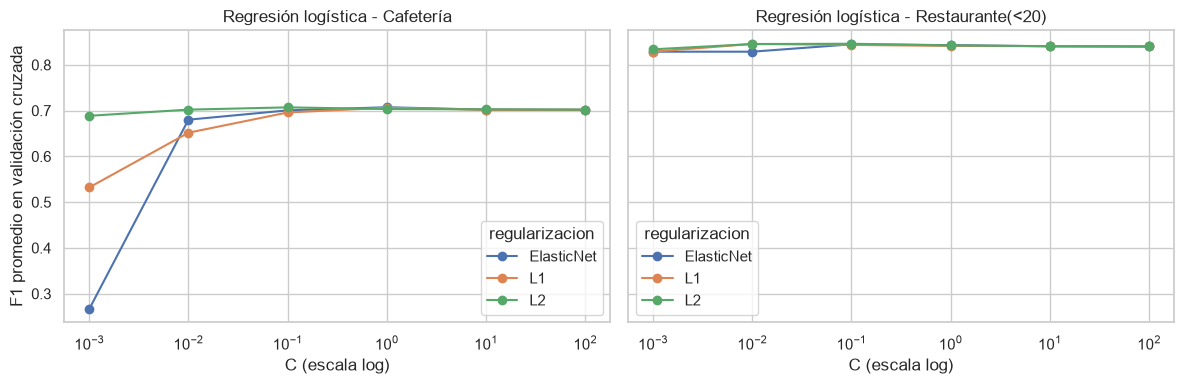

In [26]:
NOMBRE_REG = {0: "L2", 1: "L1", 0.5: "ElasticNet"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cupon in zip(axes, CUPONES):
    cv = pd.DataFrame(modelos[("Regresión logística", cupon)].cv_results_)
    cv["regularizacion"] = cv["param_modelo__l1_ratio"].map(NOMBRE_REG)
    curvas = cv.groupby(["regularizacion", "param_modelo__C"])["mean_test_score"].max().unstack(0)
    curvas.plot(ax=ax, marker="o", logx=True)
    ax.set_title(f"Regresión logística - {cupon}")
    ax.set_xlabel("C (escala log)")
    ax.set_ylabel("F1 promedio en validación cruzada")
plt.tight_layout()
plt.show()

### 3.6 Evaluación sobre test

===== Regresión logística - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.701     0.682     0.691       399
          Sí      0.689     0.708     0.698       397

    accuracy                          0.695       796
   macro avg      0.695     0.695     0.695       796
weighted avg      0.695     0.695     0.695       796

===== Regresión logística - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.611     0.340     0.437       162
          Sí      0.769     0.911     0.834       392

    accuracy                          0.744       554
   macro avg      0.690     0.625     0.635       554
weighted avg      0.723     0.744     0.718       554



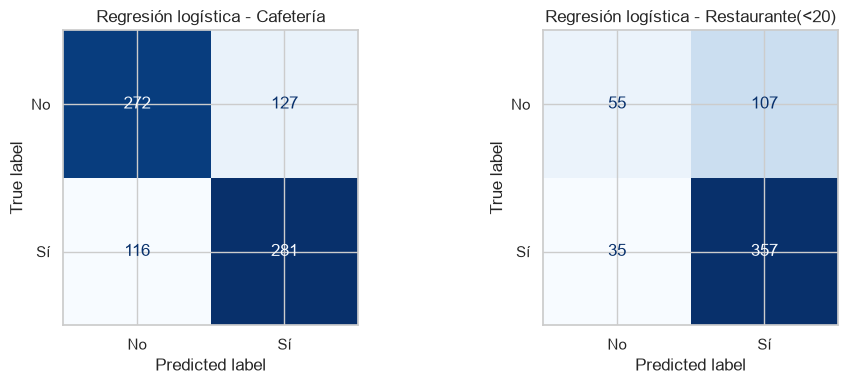

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Regresión logística,0.6887,0.7078,0.6981,0.6817,0.6947
Restaurante(<20),Regresión logística,0.7694,0.9107,0.8341,0.3395,0.7437


In [27]:
mostrar_evaluacion("Regresión logística")

### 3.7 Conclusiones de la regresión logística

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test |
|:---|:---|:---:|:---:|:---:|
| Cafetería | ElasticNet (`l1_ratio=0.5`), `saga`, `C=1` | 0.707 | 0.698 | 0.682 |
| Restaurante(<20) | L2, `lbfgs`, `C=0.1` | 0.846 | 0.834 | 0.340 |

- **Tipo de regularización y solver:** en ambos cupones las mejores configuraciones están prácticamente empatadas (diferencias < 0.001 en F1). Con L2, los cuatro solvers llegan a la misma solución, lo que es esperable porque optimizan la misma función convexa; el solver afecta la velocidad de convergencia, no el resultado. El hiperparámetro que realmente importa es **`C`**: con valores muy pequeños (regularización fuerte) el desempeño cae, como se ve en la gráfica 3.5.
- **El F1 en test es muy similar al de validación cruzada**, lo que indica que el modelo no está sobreajustado y que la estimación de la validación cruzada es confiable.
- **Cafetería:** el modelo es equilibrado entre clases (precisión y recall ≈ 0.69-0.71 para ambas).
- **Restaurante(<20):** el F1 de la clase "Sí" es alto (0.834), pero en buena parte porque el modelo tiende a predecir "Sí": el **recall de la clase "No" es solo 0.34**, es decir, identifica apenas 1 de cada 3 rechazos. Esto es un efecto del desbalance de clases que se evaluará en la Actividad 6.


## 4. Árboles de decisión

### 4.1 Pipeline y espacio de búsqueda
El pipeline usa el preprocesador **sin escalado**: los árboles dividen por umbrales sobre cada variable, por lo que la escala no afecta las particiones. La codificación ordinal es especialmente adecuada aquí, porque un umbral como `edad <= 2.5` agrupa rangos de edad contiguos.

Se exploran:
- **`max_depth`** (profundidad máxima): controla la complejidad del árbol. Valores bajos → modelos simples que pueden subajustar; `None` → el árbol crece hasta que las hojas son puras (riesgo de sobreajuste).
- **`min_samples_leaf`** (mínimo de muestras por hoja): evita hojas con muy pocos registros, que suelen capturar ruido.
- **`criterion`** (criterio de división): `gini` (impureza de Gini), `entropy` y `log_loss` (ganancia de información). En scikit-learn, `entropy` y `log_loss` son equivalentes para clasificación; se incluyen ambos para verificarlo.

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

def crear_pipeline_arbol():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=False)),
        ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])

GRID_ARBOL = {
    "modelo__max_depth": [3, 5, 7, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
}
print("Combinaciones a evaluar por cupón:", np.prod([len(v) for v in GRID_ARBOL.values()]), "x 5 folds")

Combinaciones a evaluar por cupón: 90 x 5 folds


### 4.2 Búsqueda de hiperparámetros: Cafetería

In [29]:
arbol_cafe = buscar_hiperparametros(crear_pipeline_arbol(), GRID_ARBOL, "Cafetería", "Árbol de decisión")
top_configuraciones(arbol_cafe)

Árbol de decisión - Cafetería
  Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
  F1 en validación cruzada: 0.7210


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
39,entropy,5,50,0.720999,0.017448,1
69,log_loss,5,50,0.720999,0.017448,1
9,gini,5,50,0.720208,0.016433,3
35,entropy,5,1,0.711333,0.010309,4
65,log_loss,5,1,0.711333,0.010309,4


### 4.3 Búsqueda de hiperparámetros: Restaurante(<20)

In [30]:
arbol_rest = buscar_hiperparametros(crear_pipeline_arbol(), GRID_ARBOL, "Restaurante(<20)", "Árbol de decisión")
top_configuraciones(arbol_rest)

Árbol de decisión - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}
  F1 en validación cruzada: 0.8429


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
2,gini,3,10,0.842930,0.004276,1
1,gini,3,5,0.841959,0.003616,2
8,gini,5,20,0.841847,0.008912,3
0,gini,3,1,0.841278,0.003699,4
18,gini,10,20,0.840767,0.008129,5


### 4.4 Efecto de los hiperparámetros
- **Mapa de calor:** F1 promedio en validación cruzada para cada combinación de profundidad y mínimo de muestras por hoja (con el mejor criterio en cada celda).
- **Curvas de entrenamiento vs. validación:** permiten ver a partir de qué profundidad el árbol empieza a sobreajustar (el F1 de entrenamiento sigue subiendo mientras el de validación se estanca o baja).

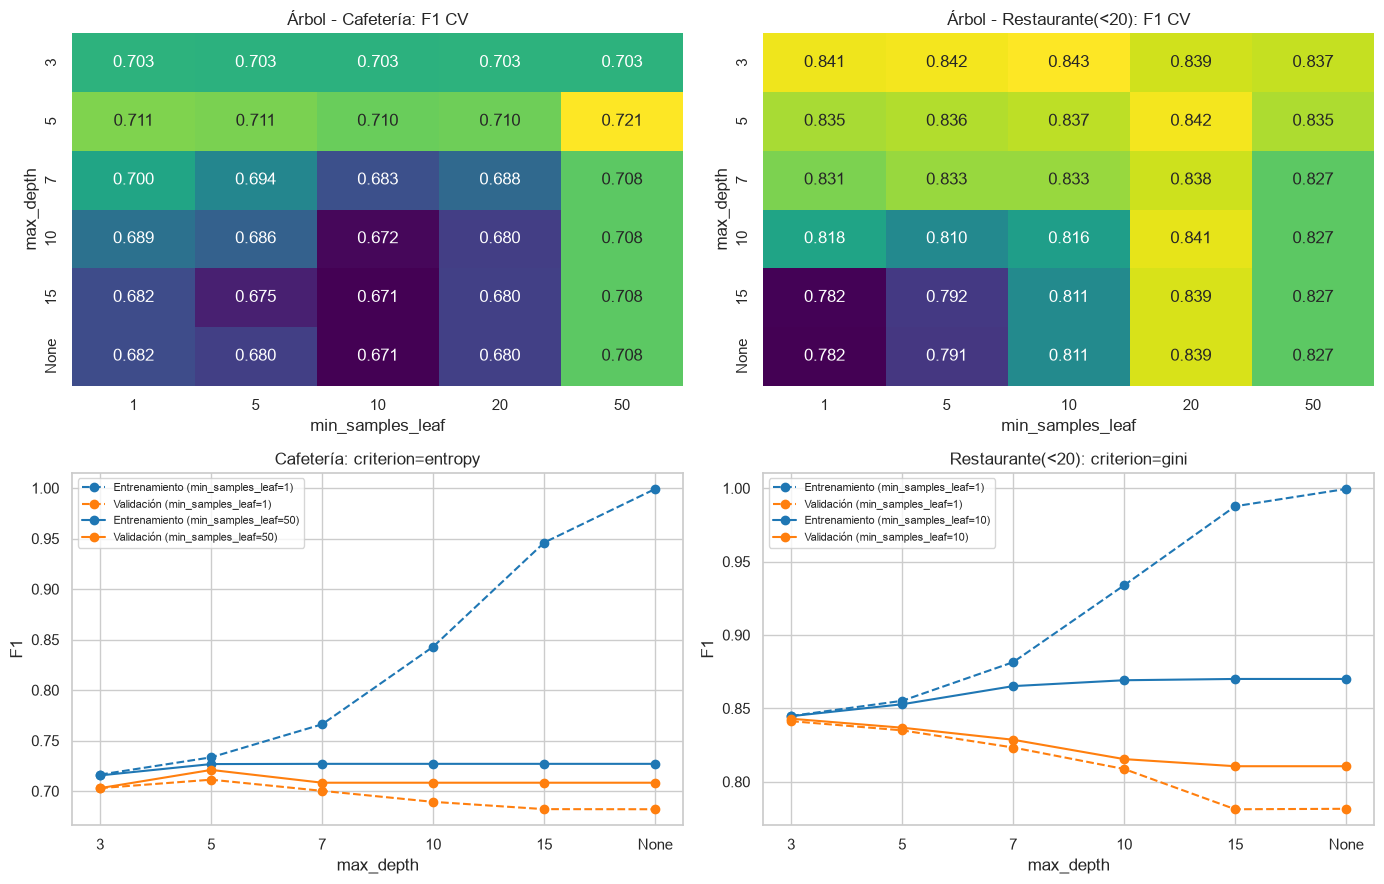

,Cafetería,Restaurante(<20)
param_modelo__criterion,,
entropy,0.7210,0.8407
gini,0.7202,0.8429
log_loss,0.7210,0.8407


In [31]:
def preparar_cv_arbol(busqueda):
    cv = pd.DataFrame(busqueda.cv_results_)
    cv["max_depth"] = cv["param_modelo__max_depth"].astype(object).where(cv["param_modelo__max_depth"].notna(), "None").astype(str)
    return cv

orden_prof = [str(v) for v in GRID_ARBOL["modelo__max_depth"]]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j, cupon in enumerate(CUPONES):
    cv = preparar_cv_arbol(modelos[("Árbol de decisión", cupon)])

    mapa = cv.pivot_table(index="max_depth", columns="param_modelo__min_samples_leaf",
                          values="mean_test_score", aggfunc="max").loc[orden_prof]
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="viridis", ax=axes[0, j], cbar=False)
    axes[0, j].set_title(f"Árbol - {cupon}: F1 CV")
    axes[0, j].set_xlabel("min_samples_leaf")

    # Curvas con el mejor criterio: sin restricción de hojas (min_samples_leaf=1) vs. el mejor min_samples_leaf
    mejor = modelos[("Árbol de decisión", cupon)].best_params_
    for msl, estilo in [(1, "--"), (mejor["modelo__min_samples_leaf"], "-")]:
        sub = cv[(cv["param_modelo__criterion"] == mejor["modelo__criterion"]) &
                 (cv["param_modelo__min_samples_leaf"] == msl)].set_index("max_depth").loc[orden_prof]
        axes[1, j].plot(orden_prof, sub["mean_train_score"], estilo, marker="o", color="tab:blue", label=f"Entrenamiento (min_samples_leaf={msl})")
        axes[1, j].plot(orden_prof, sub["mean_test_score"], estilo, marker="o", color="tab:orange", label=f"Validación (min_samples_leaf={msl})")
    axes[1, j].set_title(f"{cupon}: criterion={mejor['modelo__criterion']}")
    axes[1, j].set_xlabel("max_depth")
    axes[1, j].set_ylabel("F1")
    axes[1, j].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Comparación de criterios (mejor F1 alcanzado con cada uno)
pd.DataFrame({cupon: pd.DataFrame(modelos[("Árbol de decisión", cupon)].cv_results_)
              .groupby("param_modelo__criterion")["mean_test_score"].max() for cupon in CUPONES}).round(4)

### 4.5 Visualización de los primeros niveles de los árboles
Se muestran los 3 primeros niveles de cada árbol óptimo. Las variables ordinales aparecen con su código numérico (posición en el orden del diccionario, empezando en 0); por ejemplo, para las frecuencias: 0 = nunca, 1 = menos de 1, 2 = 1 a 3, 3 = 4 a 8, 4 = más de 8. Las variables one-hot aparecen como `variable_valor <= 0.5` (es decir, **no** toma ese valor hacia la izquierda).

Cafetería: profundidad = 5, hojas = 24


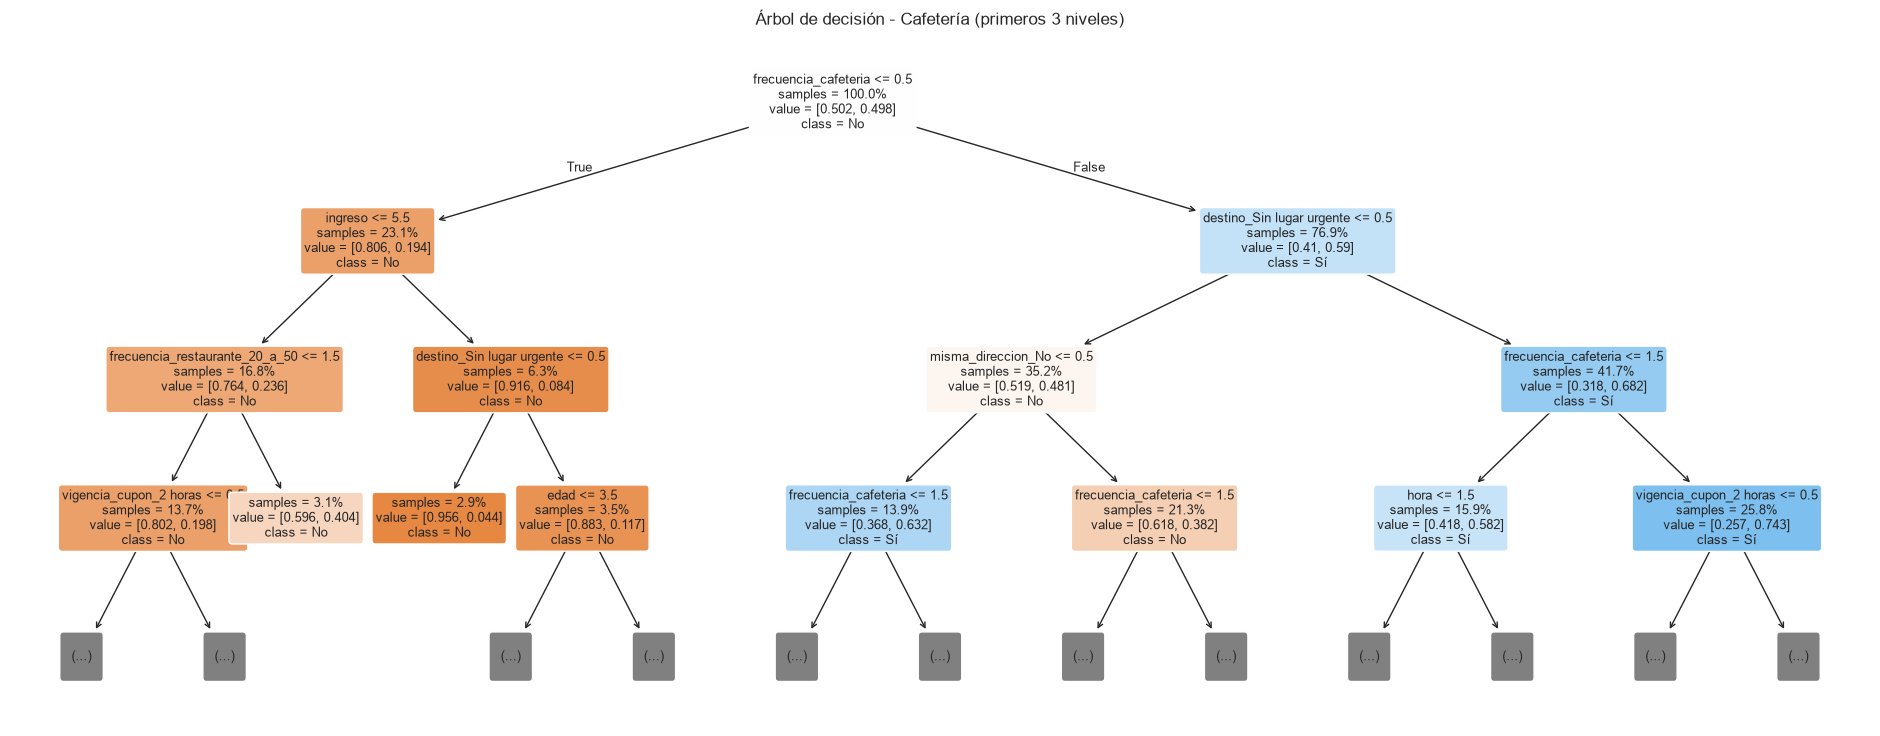

Restaurante(<20): profundidad = 3, hojas = 8


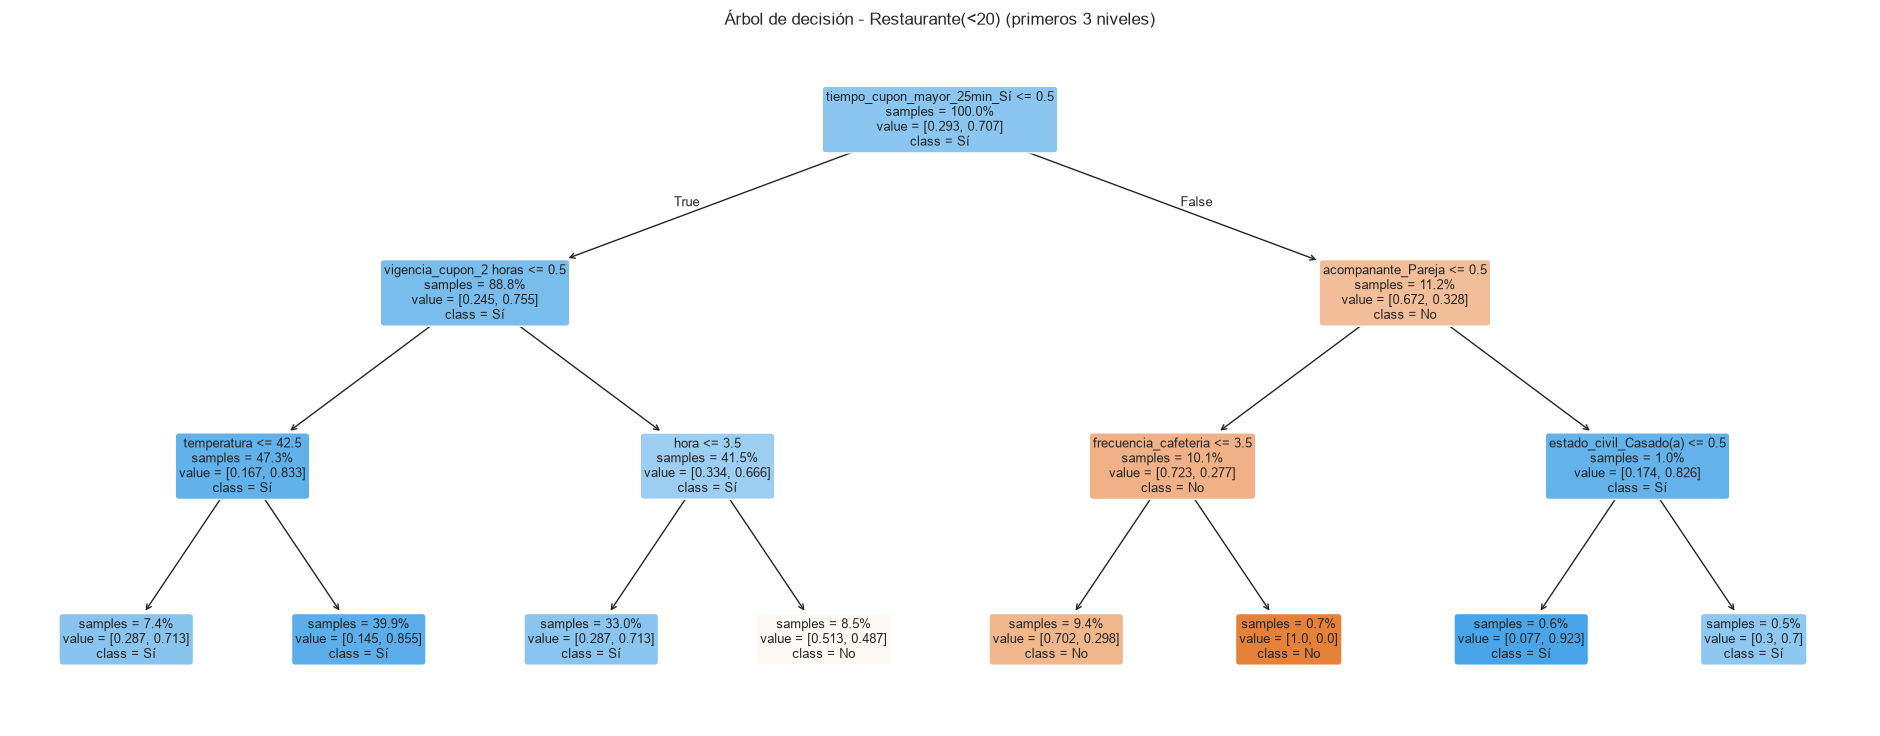

In [32]:
def nombres_variables(pipeline):
    return [n.split("__", 1)[1] for n in pipeline.named_steps["preprocesamiento"].get_feature_names_out()]

for cupon in CUPONES:
    mejor_arbol = modelos[("Árbol de decisión", cupon)].best_estimator_
    arbol = mejor_arbol.named_steps["modelo"]
    print(f"{cupon}: profundidad = {arbol.get_depth()}, hojas = {arbol.get_n_leaves()}")
    plt.figure(figsize=(24, 9))
    plot_tree(arbol, max_depth=3, feature_names=nombres_variables(mejor_arbol), class_names=["No", "Sí"],
              filled=True, rounded=True, impurity=False, proportion=True, fontsize=9)
    plt.title(f"Árbol de decisión - {cupon} (primeros 3 niveles)")
    plt.show()

### 4.6 Evaluación sobre test

===== Árbol de decisión - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.714     0.644     0.677       399
          Sí      0.674     0.741     0.706       397

    accuracy                          0.692       796
   macro avg      0.694     0.692     0.692       796
weighted avg      0.694     0.692     0.692       796

===== Árbol de decisión - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.633     0.383     0.477       162
          Sí      0.781     0.908     0.840       392

    accuracy                          0.755       554
   macro avg      0.707     0.645     0.658       554
weighted avg      0.737     0.755     0.734       554



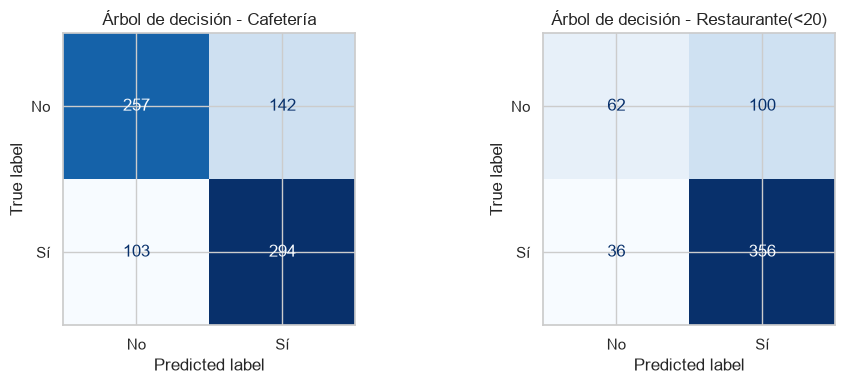

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Árbol de decisión,0.6743,0.7406,0.7059,0.6441,0.6922
Restaurante(<20),Árbol de decisión,0.7807,0.9082,0.8396,0.3827,0.7545


In [33]:
mostrar_evaluacion("Árbol de decisión")

### 4.7 Conclusiones del árbol de decisión

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test | Tamaño |
|:---|:---|:---:|:---:|:---:|:---:|
| Cafetería | `entropy`, `max_depth=5`, `min_samples_leaf=50` | 0.721 | 0.706 | 0.644 | 24 hojas |
| Restaurante(<20) | `gini`, `max_depth=3`, `min_samples_leaf=10` | 0.843 | 0.840 | 0.383 | 8 hojas |

- **Los mejores árboles son poco profundos.** Las curvas de entrenamiento vs. validación (líneas punteadas, `min_samples_leaf=1`) muestran el sobreajuste típico de los árboles: con `max_depth=15` el F1 de entrenamiento llega a 0.97 (Cafetería) y 0.99 (Restaurante(<20)), mientras que el de validación cae a 0.68 y 0.78, respectivamente. Exigir un mínimo de muestras por hoja (líneas continuas) cierra esa brecha: ambos hiperparámetros actúan como regularización.
- **El criterio de división casi no importa** (diferencias ≤ 0.002 en F1). Como se esperaba, `entropy` y `log_loss` dan exactamente el mismo resultado.
- **Reglas principales (primeros niveles):**
  - **Cafetería:** la primera división es `frecuencia_cafeteria`: quienes **nunca** van a cafeterías tienden a rechazar el cupón. Luego aparecen el `destino` ("Sin lugar urgente" favorece la aceptación), el `ingreso`, la `vigencia_cupon` y la `hora`.
  - **Restaurante(<20):** la primera división es la **distancia**: si el restaurante está a más de 25 minutos, el árbol predice rechazo (salvo si viaja con su pareja). Si está cerca, predice aceptación, excepto con cupones de 2 horas en horas tardías (`hora` > 6:00 p.m., es decir, 10:00 p.m.).
- Frente a la regresión logística, el árbol tiene un desempeño muy similar en ambos cupones, con la ventaja de ser directamente interpretable como reglas.


## 5. Random Forest

### 5.1 Pipeline y espacio de búsqueda
Random Forest combina muchos árboles entrenados sobre muestras *bootstrap* de los datos y, en cada división, sobre un subconjunto aleatorio de variables. Promediar árboles poco correlacionados reduce la varianza de un árbol individual, por lo que suele generalizar mejor. Igual que con el árbol, se usa el preprocesador sin escalado.

Se exploran:
- **`n_estimators`** (número de árboles): más árboles → predicciones más estables, con rendimientos decrecientes y mayor costo computacional.
- **`max_depth`** (profundidad máxima de cada árbol).
- **`min_samples_leaf`** (mínimo de muestras por hoja).
- **`max_features`** (fracción de variables consideradas en cada división): controla qué tan distintos son los árboles entre sí. `sqrt` ≈ 8 de las 62 columnas; `0.3` ≈ 19.

In [34]:
from sklearn.ensemble import RandomForestClassifier

def crear_pipeline_rf():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=False)),
        ("modelo", RandomForestClassifier(random_state=RANDOM_STATE)),
    ])

GRID_RF = {
    "modelo__n_estimators": [100, 300, 500],
    "modelo__max_depth": [10, 20, None],
    "modelo__min_samples_leaf": [1, 2, 5, 10],
    "modelo__max_features": ["sqrt", 0.3],
}
print("Combinaciones a evaluar por cupón:", np.prod([len(v) for v in GRID_RF.values()]), "x 5 folds")

Combinaciones a evaluar por cupón: 72 x 5 folds


### 5.2 Búsqueda de hiperparámetros: Cafetería

In [35]:
rf_cafe = buscar_hiperparametros(crear_pipeline_rf(), GRID_RF, "Cafetería", "Random Forest")
top_configuraciones(rf_cafe)

Random Forest - Cafetería
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  F1 en validación cruzada: 0.7589


,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_test_score,std_test_score,rank_test_score
50,None,sqrt,1,500,0.758930,0.012780,1
61,None,0.3,1,300,0.758604,0.009853,2
60,None,0.3,1,100,0.756998,0.010475,3
49,None,sqrt,1,300,0.756932,0.013094,4
37,20,0.3,1,300,0.756737,0.008894,5


### 5.3 Búsqueda de hiperparámetros: Restaurante(<20)

In [36]:
rf_rest = buscar_hiperparametros(crear_pipeline_rf(), GRID_RF, "Restaurante(<20)", "Random Forest")
top_configuraciones(rf_rest)

Random Forest - Restaurante(<20)
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  F1 en validación cruzada: 0.8574


,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_test_score,std_test_score,rank_test_score
50,None,sqrt,1,500,0.857402,0.008369,1
26,20,sqrt,1,500,0.856970,0.007825,2
49,None,sqrt,1,300,0.855513,0.004989,3
25,20,sqrt,1,300,0.855026,0.006164,4
14,10,0.3,1,500,0.854281,0.001050,5


### 5.4 Efecto de los hiperparámetros
F1 de validación cruzada en función de cada hiperparámetro, fijando los demás en su mejor valor.

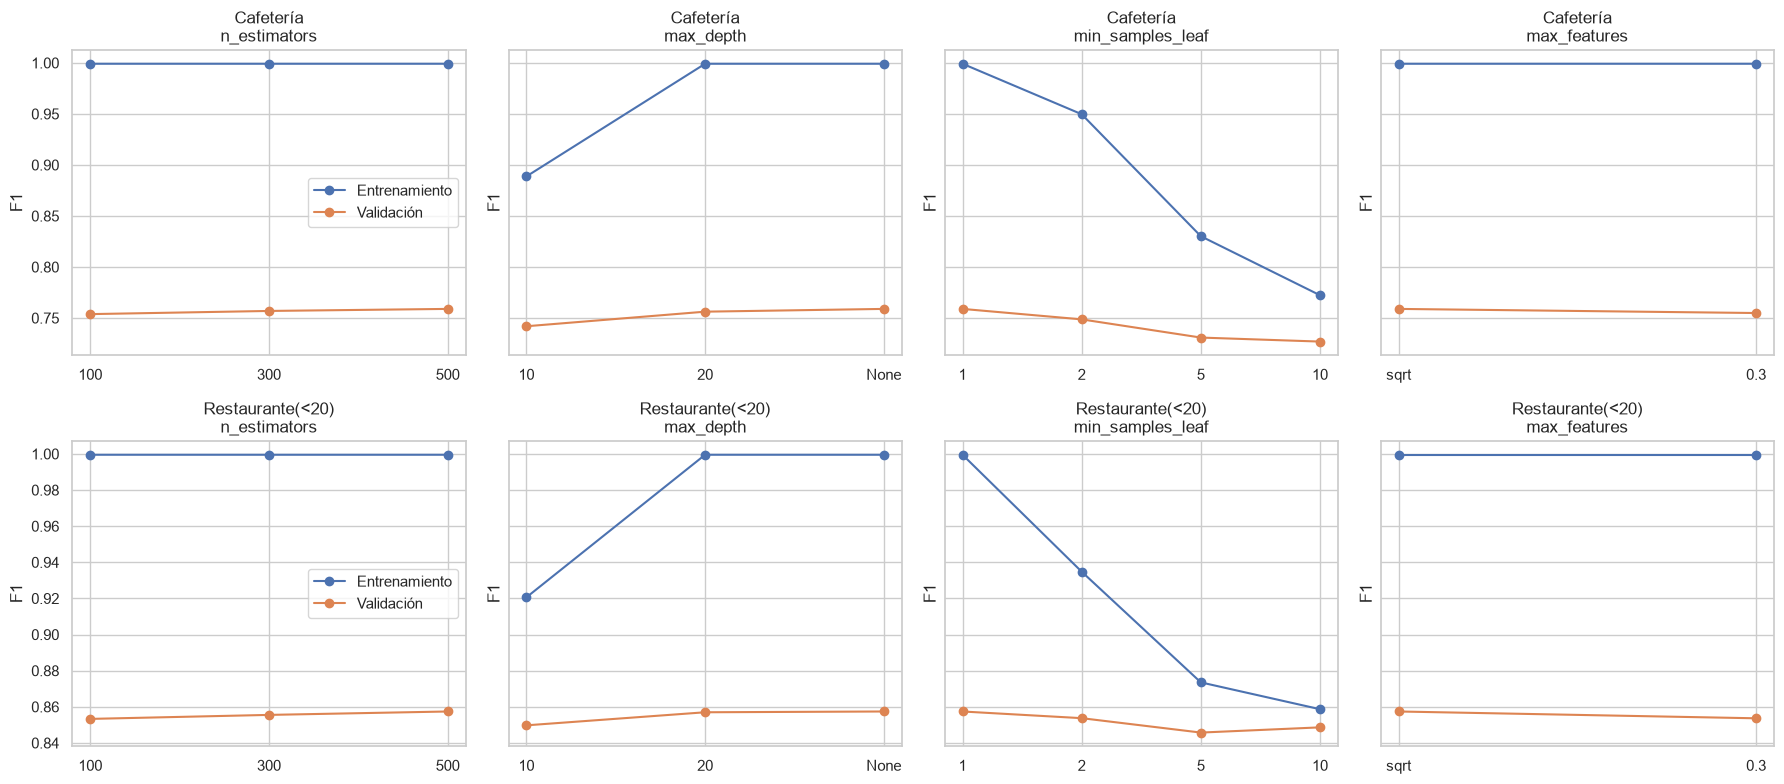

In [37]:
HIPER_RF = ["modelo__n_estimators", "modelo__max_depth", "modelo__min_samples_leaf", "modelo__max_features"]

fig, axes = plt.subplots(2, len(HIPER_RF), figsize=(18, 8), sharey="row")
for i, cupon in enumerate(CUPONES):
    busqueda = modelos[("Random Forest", cupon)]
    cv = pd.DataFrame(busqueda.cv_results_)
    for j, h in enumerate(HIPER_RF):
        filtro = np.ones(len(cv), dtype=bool)
        for otro in HIPER_RF:
            if otro != h:
                mejor = busqueda.best_params_[otro]
                col = cv[f"param_{otro}"]
                filtro &= col.isna().to_numpy() if mejor is None else (col == mejor).to_numpy()
        sub = cv[filtro]
        etiquetas = sub[f"param_{h}"].astype(object).where(sub[f"param_{h}"].notna(), "None").astype(str)
        ax = axes[i, j]
        ax.plot(etiquetas, sub["mean_train_score"], marker="o", label="Entrenamiento")
        ax.plot(etiquetas, sub["mean_test_score"], marker="o", label="Validación")
        ax.set_title(f"{cupon}\n{h.replace('modelo__', '')}")
        ax.set_ylabel("F1")
        if j == 0:
            ax.legend()
plt.tight_layout()
plt.show()

### 5.5 Evaluación sobre test

===== Random Forest - Cafetería (test) =====
              precision    recall  f1-score   support

          No      0.768     0.779     0.774       399
          Sí      0.775     0.763     0.769       397

    accuracy                          0.771       796
   macro avg      0.771     0.771     0.771       796
weighted avg      0.771     0.771     0.771       796

===== Random Forest - Restaurante(<20) (test) =====
              precision    recall  f1-score   support

          No      0.713     0.414     0.523       162
          Sí      0.793     0.931     0.857       392

    accuracy                          0.780       554
   macro avg      0.753     0.672     0.690       554
weighted avg      0.770     0.780     0.759       554



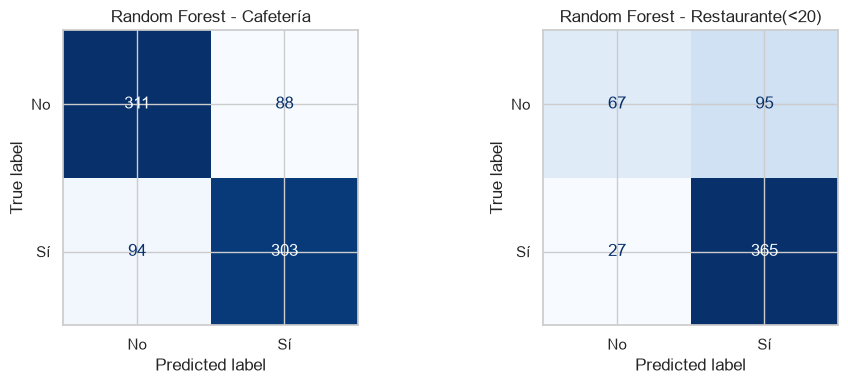

,algoritmo,precision,recall,f1,recall_No,accuracy
cupon,,,,,,
Cafetería,Random Forest,0.7749,0.7632,0.7690,0.7794,0.7714
Restaurante(<20),Random Forest,0.7935,0.9311,0.8568,0.4136,0.7798


In [38]:
mostrar_evaluacion("Random Forest")

### 5.6 Conclusiones de Random Forest

| Cupón | Mejor configuración | F1 CV | F1 test | Recall "No" test |
|:---|:---|:---:|:---:|:---:|
| Cafetería | 500 árboles, `max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"` | 0.759 | 0.769 | 0.779 |
| Restaurante(<20) | 500 árboles, `max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"` | 0.857 | 0.857 | 0.414 |

- **Es el mejor de los tres algoritmos en ambos cupones**, con una mejora especialmente clara en Cafetería (+0.06 a 0.07 de F1 frente a la regresión logística y el árbol).
- **A diferencia del árbol individual, los árboles del bosque rinden mejor sin restricción de profundidad.** Cada árbol profundo sobreajusta por separado (F1 de entrenamiento ≈ 1), pero al promediar cientos de árboles entrenados con muestras y variables distintas, la varianza se reduce y el conjunto generaliza bien. Por eso el F1 de test es igual o mayor que el de validación cruzada.
- **`n_estimators`** muestra rendimientos decrecientes: pasar de 100 a 500 árboles mejora el F1 en milésimas. El mejor valor está en el borde de la grilla (500), pero la tendencia sugiere que más árboles no cambiarían el resultado de forma relevante y sí aumentarían el costo computacional.
- **Restaurante(<20)** mantiene el mismo problema que los otros modelos: aunque el recall de "No" mejora un poco (0.41), el modelo sigue identificando menos de la mitad de los rechazos. Esto motiva la evaluación del balanceo de clases en la Actividad 6.
